**Student ID:** MS26910222  
**Name:** N.G. Wickramathilaka  
**Module:** IT5092 – Neuroscience and Neurocomputing (Lab Sheet 6)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from config import LEARNING_RATE, EPOCHS, NOISE_LEVELS, SEED
from models.hebbian import train_hebbian
from models.associative_memory import train_associative_memory, recall_pattern
from utils.patterns import make_demo_patterns, add_noise
from utils.metrics import recall_accuracy
from utils.plotting import plot_weight_history, show_pattern

np.random.seed(SEED)

### Part A: Hebbian learning

In [2]:
""" Part A – Basic Hebbian Learning

# In this section, you will train a simple Hebbian model on a small correlated dataset.
# You will observe how the weights change across epochs.

"""

# Correlated dataset
X_corr = np.array([
    [1.0, 1.0],
    [0.9, 1.1],
    [1.1, 0.95],
    [1.0, 0.9]
])

# TODO 2:
# Train the Hebbian model using X_corr
# Save the outputs as w_final and history
w_final, history = train_hebbian(X_corr, epochs=EPOCHS, lr=LEARNING_RATE)

print("Initial weights (before training):", np.round(np.random.default_rng(SEED).uniform(0.0, 0.1, size=2), 4))
print("Final weights after", EPOCHS, "epochs:", np.round(w_final, 4))
print("History shape (epochs, weights):", history.shape)

# Sanity check: with zero initial weights the output y = w.x is always 0,
# so pure Hebbian learning cannot start (this is why small random weights are used).
w_zero, _ = train_hebbian(X_corr, w_init=[0.0, 0.0])
print("Final weights if training starts from zero:", w_zero)

Initial weights (before training): [0.0774 0.0439]
Final weights after 10 epochs: [83.2477 80.9296]
History shape (epochs, weights): (10, 2)
Final weights if training starts from zero: [0. 0.]


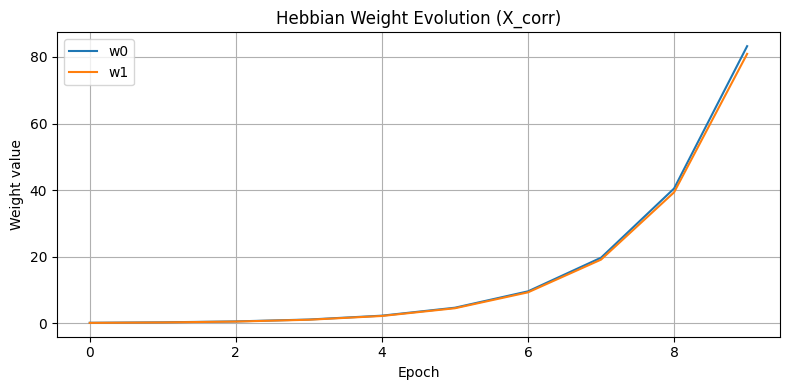

Epoch   w0         w1         ||w||
    1      0.1424     0.1070     0.1781
    2      0.2760     0.2369     0.3637
    3      0.5508     0.5040     0.7466
    4      1.1160     1.0535     1.5347
    5      2.2781     2.1837     3.1557
    6      4.6683     4.5081     6.4897
    7      9.5839     9.2887    13.3466
    8     19.6937    19.1207    27.4489
    9     40.4857    39.3418    56.4524
   10     83.2477    80.9296   116.1025

Growth factor of ||w|| per epoch: [2.042 2.053 2.055 2.056 2.056 2.057 2.057 2.057 2.057]
Final direction w/||w||: [0.717  0.6971]
First principal direction of the inputs: [0.7115 0.7027]


In [3]:
# TODO 3:
# Plot the weight evolution
plot_weight_history(history, title="Hebbian Weight Evolution (X_corr)")

# Weight vector length and direction per epoch
norms = np.linalg.norm(history, axis=1)
print("Epoch   w0         w1         ||w||")
for e, (wv, nrm) in enumerate(zip(history, norms), start=1):
    print(f"{e:5d}   {wv[0]:9.4f}  {wv[1]:9.4f}  {nrm:9.4f}")

print("\nGrowth factor of ||w|| per epoch:", np.round(norms[1:] / norms[:-1], 3))
print("Final direction w/||w||:", np.round(w_final / np.linalg.norm(w_final), 4))

# Compare with the principal direction of the input correlation matrix
C_in = X_corr.T @ X_corr / len(X_corr)
eigvals, eigvecs = np.linalg.eigh(C_in)
pc1 = np.abs(eigvecs[:, -1])
print("First principal direction of the inputs:", np.round(pc1, 4))

### Part B: Associative memory

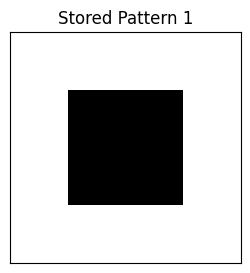

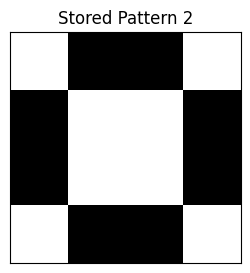

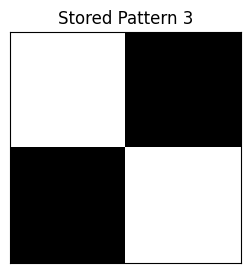

W shape: (16, 16)
W is symmetric: True
Diagonal is zero: True
Overlap between stored patterns (p_i . p_j):
 [[16 -8  0]
 [-8 16  0]
 [ 0  0 16]]


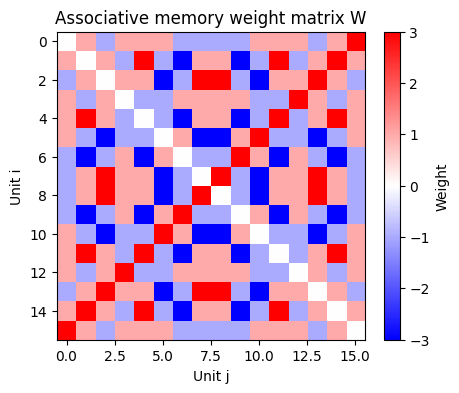

Pattern 1 stable: True
Pattern 2 stable: True
Pattern 3 stable: True


In [4]:
"""Part B – Associative Memory

In this section, you will store simple bipolar patterns using Hebbian learning.
Then you will provide a noisy cue and test whether the system can recover the original pattern.

"""
patterns = make_demo_patterns()

for i, p in enumerate(patterns):
    show_pattern(p, title=f"Stored Pattern {i+1}")

# TODO 6:
# Train the associative memory matrix W using the stored patterns
W = train_associative_memory(patterns)

print("W shape:", W.shape)
print("W is symmetric:", np.allclose(W, W.T))
print("Diagonal is zero:", np.all(np.diag(W) == 0))
print("Overlap between stored patterns (p_i . p_j):\n", patterns @ patterns.T)

plt.figure(figsize=(5, 4))
plt.imshow(W, cmap="bwr")
plt.colorbar(label="Weight")
plt.title("Associative memory weight matrix W")
plt.xlabel("Unit j")
plt.ylabel("Unit i")
plt.show()

# Check that every stored pattern is a stable state (recalls itself)
for i, p in enumerate(patterns):
    print(f"Pattern {i+1} stable:", np.array_equal(recall_pattern(W, p), p))

Number of flipped pixels in the noisy input: 4 out of 16


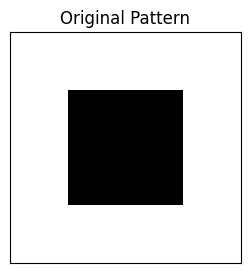

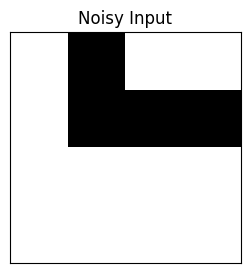

In [5]:
target = patterns[0]
noisy = add_noise(target, noise_level=0.25)

# TODO 7:
# Recall the pattern from the noisy input
# Save it as recalled
recalled = recall_pattern(W, noisy, steps=5)

print("Number of flipped pixels in the noisy input:", int(np.sum(noisy != target)), "out of", len(target))

show_pattern(target, title="Original Pattern")
show_pattern(noisy, title="Noisy Input")

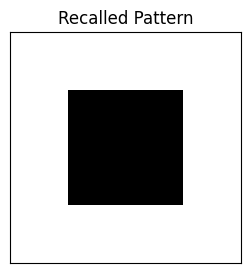

Noisy input accuracy (before recall): 0.75
Recall accuracy (after recall)      : 1.0
Perfect recall: True


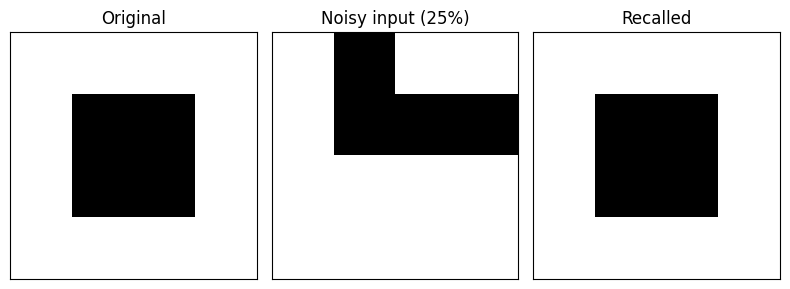

In [6]:
# TODO 8:
# Display the recalled pattern
# Compute and print recall accuracy
show_pattern(recalled, title="Recalled Pattern")

acc = recall_accuracy(target, recalled)
print("Noisy input accuracy (before recall):", recall_accuracy(target, noisy))
print("Recall accuracy (after recall)      :", acc)
print("Perfect recall:", np.array_equal(target, recalled))

# Side-by-side view
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, img, ttl in zip(axes, [target, noisy, recalled], ["Original", "Noisy input (25%)", "Recalled"]):
    ax.imshow(img.reshape(4, 4), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(ttl)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

Section 4 – Noise experiment

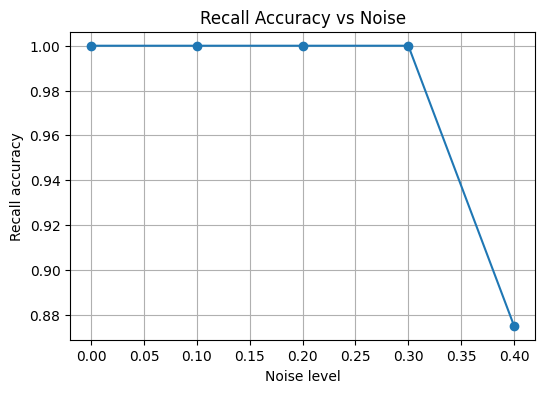

noise = 0.0  (0 pixels flipped)  ->  recall accuracy = 1.000
noise = 0.1  (1 pixels flipped)  ->  recall accuracy = 1.000
noise = 0.2  (3 pixels flipped)  ->  recall accuracy = 1.000
noise = 0.3  (4 pixels flipped)  ->  recall accuracy = 1.000
noise = 0.4  (6 pixels flipped)  ->  recall accuracy = 0.875


In [7]:
accs = []

for nl in NOISE_LEVELS:
    noisy = add_noise(target, noise_level=nl)
    recalled = recall_pattern(W, noisy, steps=5)
    acc = recall_accuracy(target, recalled)
    accs.append(acc)

plt.figure(figsize=(6,4))
plt.plot(NOISE_LEVELS, accs, marker='o')
plt.xlabel("Noise level")
plt.ylabel("Recall accuracy")
plt.title("Recall Accuracy vs Noise")
plt.grid(True)
plt.show()

for nl, acc in zip(NOISE_LEVELS, accs):
    print(f"noise = {nl:.1f}  ({int(len(target) * nl)} pixels flipped)  ->  recall accuracy = {acc:.3f}")

Averaged noise experiment

The cell above uses one fixed noisy version per noise level, so the result depends on which pixels happened to be flipped. Below, recall is repeated for 300 random noisy cues per pattern for all three stored patterns, and both the mean accuracy and the percentage of perfect recalls are reported.

noise = 0.0  mean accuracy = 1.000  perfect recall = 100.0%
noise = 0.1  mean accuracy = 0.990  perfect recall =  84.1%
noise = 0.2  mean accuracy = 0.926  perfect recall =  46.4%
noise = 0.3  mean accuracy = 0.933  perfect recall =  53.1%
noise = 0.4  mean accuracy = 0.777  perfect recall =  17.0%
noise = 0.5  mean accuracy = 0.494  perfect recall =   0.0%


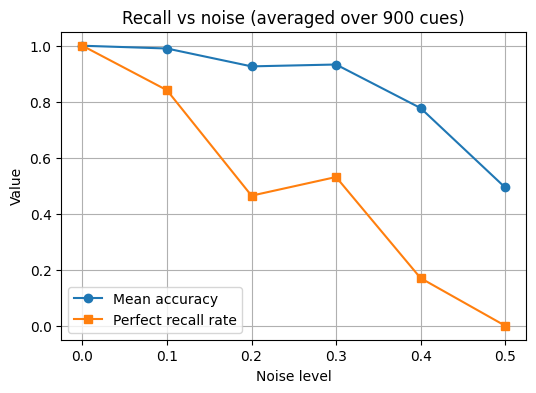

In [8]:
rng = np.random.default_rng(SEED)
noise_grid = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
n_trials = 300

mean_acc, perfect_rate = [], []
for nl in noise_grid:
    trial_acc = []
    for p in patterns:
        for _ in range(n_trials):
            cue = add_noise(p, noise_level=nl, rng=rng)
            out = recall_pattern(W, cue, steps=5)
            trial_acc.append(recall_accuracy(p, out))
    trial_acc = np.array(trial_acc)
    mean_acc.append(trial_acc.mean())
    perfect_rate.append(np.mean(trial_acc == 1.0))

for nl, m, pr in zip(noise_grid, mean_acc, perfect_rate):
    print(f"noise = {nl:.1f}  mean accuracy = {m:.3f}  perfect recall = {100*pr:5.1f}%")

plt.figure(figsize=(6, 4))
plt.plot(noise_grid, mean_acc, marker='o', label="Mean accuracy")
plt.plot(noise_grid, perfect_rate, marker='s', label="Perfect recall rate")
plt.xlabel("Noise level")
plt.ylabel("Value")
plt.title(f"Recall vs noise (averaged over {3*n_trials} cues)")
plt.grid(True)
plt.legend()
plt.show()

Writing Questions
1. Why does Hebbian learning strengthen some connections more than others?
2. What happens to recall performance when noise increases?
3. What is one limitation of Hebbian learning?

### Answers to Writing Questions

**1. Why does Hebbian learning strengthen some connections more than others?**

The Hebbian change in a weight is Δw = η·x·y, so a connection only grows when its input and the output are active together, and it grows most for inputs that are consistently active whenever the neuron fires. In Part A both inputs of `X_corr` are always close to 1 and strongly correlated, so both weights grew, but *w0* ended slightly larger (83.25 vs 80.93) because the first input is on average a little larger. The final weight direction [0.717, 0.697] matches the first principal direction of the inputs [0.712, 0.703], showing that Hebbian learning strengthens connections in proportion to how strongly they are correlated with the output. In Part B the same idea gives W_ij = Σ p_i·p_j: pairs of pixels that have the same sign in all three patterns get the strongest positive weight (+3), pairs that always have opposite signs get −3, and pairs that agree in some patterns but not others end up weak (±1) because the updates partly cancel.

**2. What happens to recall performance when noise increases?**

Recall gets worse as noise increases. With 25% noise (4 of 16 pixels flipped) the network fully corrected the cue: accuracy went from 0.75 in the noisy input to 1.0 after recall. In the single-cue experiment accuracy stayed at 1.0 up to 30% noise and dropped to 0.875 at 40%. The averaged experiment (900 random cues) shows the trend more clearly: mean accuracy fell from 1.00 (no noise) to 0.99, about 0.93, 0.78 and 0.49 at 10%, 20–30%, 40% and 50% noise, and perfect recall fell from 100% to 84%, about 50%, 17% and 0%. The 20% and 30% results are almost the same because `add_noise` rounds down, so they flip 3 and 4 pixels respectively. Once about half the pixels are flipped the cue no longer carries information about the original pattern, so the network cannot recover it; small noise stays inside the pattern's "basin of attraction" and is corrected, while large noise pushes the state toward another stored pattern, its inverse or a spurious mixture state.

**3. What is one limitation of Hebbian learning?**

Basic Hebbian learning has no mechanism that limits weight growth, so the weights increase without bound. In Part A ‖w‖ roughly doubled every epoch (growth factor ≈ 2.06), reaching 116 after 10 epochs and about 2.1 × 10⁸ after 30 epochs, which is not biologically plausible and would eventually overflow; Oja's rule below fixes this by normalising the weights. A second limitation is limited storage capacity and interference between similar patterns: a Hopfield-style memory with N = 16 units can reliably store only about 0.14N ≈ 2 patterns, and here Patterns 1 and 2 overlap (p1·p2 = −8). Because of this crosstalk, flipping just 1 pixel of Pattern 1 or 2 caused recall errors in 4 of 16 cases each, while the orthogonal Pattern 3 was recalled perfectly in all 16 cases, and storing only two orthogonal patterns removed these errors completely.

### Optional Challenge – Oja's rule vs basic Hebbian learning

Oja's rule adds a decay term to the Hebbian update:

$$w_{new} = w_{old} + \eta \, y \, (x - y \, w_{old})$$

Both rules are trained on `X_corr` from the same initial weights for 30 epochs, and the length of the weight vector ‖w‖ is compared.

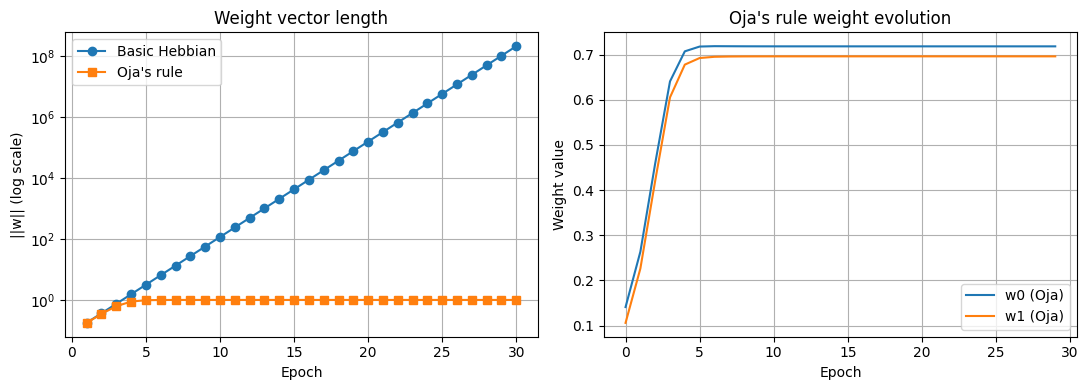

After 30 epochs:
  Basic Hebbian  w = [1.52579205e+08 1.48389842e+08]  ||w|| = 2.128e+08
  Oja's rule     w = [0.7183 0.6961]  ||w|| = 1.0003
  Hebbian direction: [0.7169 0.6972]
  Oja direction    : [0.7181 0.696 ]
  First principal direction of inputs: [0.7115 0.7027]


In [9]:
from models.hebbian import train_oja

long_epochs = 30
w_hebb, hist_hebb = train_hebbian(X_corr, epochs=long_epochs, lr=LEARNING_RATE)
w_oja,  hist_oja  = train_oja(X_corr, epochs=long_epochs, lr=LEARNING_RATE)

norm_hebb = np.linalg.norm(hist_hebb, axis=1)
norm_oja  = np.linalg.norm(hist_oja, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(range(1, long_epochs + 1), norm_hebb, marker='o', label="Basic Hebbian")
axes[0].semilogy(range(1, long_epochs + 1), norm_oja, marker='s', label="Oja's rule")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("||w|| (log scale)")
axes[0].set_title("Weight vector length"); axes[0].grid(True); axes[0].legend()

axes[1].plot(hist_oja[:, 0], label="w0 (Oja)")
axes[1].plot(hist_oja[:, 1], label="w1 (Oja)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Weight value")
axes[1].set_title("Oja's rule weight evolution"); axes[1].grid(True); axes[1].legend()
plt.tight_layout()
plt.show()

print("After", long_epochs, "epochs:")
print("  Basic Hebbian  w =", np.round(w_hebb, 2), " ||w|| = %.3e" % np.linalg.norm(w_hebb))
print("  Oja's rule     w =", np.round(w_oja, 4), " ||w|| = %.4f" % np.linalg.norm(w_oja))
print("  Hebbian direction:", np.round(w_hebb / np.linalg.norm(w_hebb), 4))
print("  Oja direction    :", np.round(w_oja / np.linalg.norm(w_oja), 4))
print("  First principal direction of inputs:", np.round(pc1, 4))

**Comparison of stability:** With basic Hebbian learning ‖w‖ grows exponentially (about ×2.06 per epoch), reaching roughly 2.1 × 10⁸ after 30 epochs, so the learning never settles. With Oja's rule the extra −η·y²·w term acts like weight decay: ‖w‖ rises to 1.000 within about 5 epochs and then stays constant, giving w ≈ [0.718, 0.696]. Both rules learn the same direction, which is the first principal direction of the inputs ([0.712, 0.703]), so Oja's rule keeps the useful part of Hebbian learning (finding the main correlation in the data) while making the weights stable and bounded.